The city of Terriertown wants to publish block-group tables built from census-style data, including data on race/ethnicity age, national origin, disability status, and poverty. Tables are used to allocate funds, draw districts, and plan services. The city will add noise using **differential privacy (DP)** and must choose a **total privacy budget, epsilon (ε)**, and split it across the tables.

This notebook is your lab bench. **You do not need to understand every line of code,** or honestly any of it. You need to Run the code, change the settings, and repeat until you come away with **settings that you can defend and and support for your team's position**.

### How to use this notebook
1. Run the notebook top to bottom once (Runtime → Run all in Colab, or Kernel → Restart & Run All in Jupyter).
2. Go to **Section 5 (your control panel)**, change ε, choose **which tables to release**, set the budget split, and re-run it.
3. Use **Sections 6–8** to see the tradeoffs and risks.
4. Use **Section 10** (or an editor of your choice) for your team's memo.

### Thinks to keep in mind
- Epsilon is a **policy dial disguised as a parameter**. Small ε means more noise and more privacy. Large ε means less noise and less privacy. Nothing in the math tells you the "right" value.
- Noise affects **small cells** (small neighborhoods, small populations) far more than big ones.
- Privacy budget is **spent per release**. More tables means more information, but less epsilon and therefore less accuracy for each one.

## Setting up

This block initializes a few things. Not much to see here.

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (8, 4)

SEED = 2026   # change to get a different synthetic city

## Generating Terriertown

To keep this self-contained, we generate data for a city of 40 block groups, with sizes from a few dozen people to a few thousand, which is realistic for U.S. geography. **Nine tables** are planned for potential release: five one-way tables (race, age, national origin, poverty, and disability) and four cross-tabulations (poverty x race, age, national origin, and disability). Each cross-tab is a separate table with its own cells.

**Each person appears in exactly one cell of each table.** People are simulated individually, so all seven tables are consistent with one another.

In [54]:
RACE_CATS    = ["White non-Hisp.", "Black", "Hispanic", "Asian", "Other"]
AGE_CATS     = ["Under 18", "18-34", "35-64", "65+"]
POV_CATS     = ["Below poverty", "At/above poverty"]
DIS_CATS     = ["Disability", "No disability"]
NAT_CATS     = ["Native-born", "Foreign-born"]

def build_tables(bg, race, age, pov, nat, dis, n_bg):
    """Turn per-person category codes into the seven release tables."""
    idx = [f"BG-{i+1:02d}" for i in range(n_bg)]
    def tab(code, ncat, cols):
        m = np.bincount(bg * ncat + code, minlength=n_bg * ncat).reshape(n_bg, ncat)
        return pd.DataFrame(m, index=idx, columns=cols)
    def cross(codes, cats):      # poverty x another variable, as its own table
        cols = [f"{p} x {c}" for p in POV_CATS for c in cats]
        return tab(pov * len(cats) + codes, 2 * len(cats), cols)
    return {
        "race":              tab(race, len(RACE_CATS), RACE_CATS),
        "age":               tab(age,  len(AGE_CATS), AGE_CATS),
        "nativity":          tab(nat,  len(NAT_CATS), NAT_CATS),
        "disability":        tab(dis,  len(DIS_CATS), DIS_CATS),
        "poverty":           tab(pov,  len(POV_CATS), POV_CATS),
        "pov_by_race":       cross(race, RACE_CATS),
        "pov_by_age":        cross(age, AGE_CATS),
        "pov_by_nativity":   cross(nat, NAT_CATS),
        "pov_by_disability": cross(dis, DIS_CATS),
    }

def make_terriertown(n_bg=40, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = np.clip(rng.lognormal(6.3, 0.9, n_bg), 25, 4000).astype(int)

    race_base = np.array([0.45, 0.20, 0.20, 0.10, 0.05])
    age_base  = np.array([0.22, 0.38, 0.28, 0.12])
    nat_base = np.array([0.85, 0.15])
    dis_base = np.array([0.15, 0.85])
    # poverty is more likely for some groups, so the cross-tabs are not boring
    race_mult = np.array([0.6, 1.6, 1.4, 0.8, 1.1])
    age_mult  = np.array([1.5, 1.2, 0.8, 0.9])
    nat_mult  = np.array([0.95, 1.15])
    dis_mult  = np.array([1.6, 0.9])
    exp_mult = (race_base @ race_mult) * (age_base @ age_mult) * (nat_base @ nat_mult) * (dis_base @ dis_mult)

    target_pov = np.clip(rng.normal(0.20, 0.07, n_bg), 0.02, 0.50)   # many near the 20% line
    nat_rate   = np.clip(rng.normal(0.15, 0.10, n_bg), 0.01, 0.50)

    bg, race, age, pov, nat, dis = [], [], [], [], [], []
    for i, p in enumerate(pop):
        r = rng.choice(5, size=p, p=rng.dirichlet(race_base * 20))
        a = rng.choice(4, size=p, p=rng.dirichlet(age_base * 50))
        n = (rng.random(p) < nat_rate[i]).astype(int)
        d = rng.choice(2, size=p, p=rng.dirichlet(dis_base * 50))
        prob = np.clip(target_pov[i] / exp_mult * race_mult[r] * age_mult[a] * nat_mult[n] * dis_mult[d], 0, 0.95)
        v = np.where(rng.random(p) < prob, 0, 1)          # 0 = below poverty
        bg.append(np.full(p, i)); race.append(r); age.append(a); pov.append(v); nat.append(n); dis.append(d)
    cat = np.concatenate
    return build_tables(cat(bg), cat(race), cat(age), cat(pov), cat(nat), cat(dis), n_bg)

TRUE = make_terriertown()
pop = TRUE["race"].sum(axis=1)
print("Tables:", list(TRUE))
print("Block-group populations:")
print(pop.describe().round(0).to_string())
print("\nA few real (unprotected) rows from the poverty-by-race table:")
TRUE["pov_by_race"].head()

Tables: ['race', 'age', 'nativity', 'disability', 'poverty', 'pov_by_race', 'pov_by_age', 'pov_by_nativity', 'pov_by_disability']
Block-group populations:
count      40.0
mean      745.0
std       577.0
min        98.0
25%       358.0
50%       509.0
75%       973.0
max      2813.0

A few real (unprotected) rows from the poverty-by-race table:


,Below poverty x White non-Hisp.,Below poverty x Black,Below poverty x Hispanic,Below poverty x Asian,Below poverty x Other,At/above poverty x White non-Hisp.,At/above poverty x Black,At/above poverty x Hispanic,At/above poverty x Asian,At/above poverty x Other
BG-01,22,8,19,3,4,119,19,37,20,15
BG-02,27,30,29,14,2,257,98,95,116,8
BG-03,1,5,2,1,0,34,24,13,10,8
BG-04,140,94,163,111,20,659,102,223,354,46
BG-05,63,84,38,19,12,405,148,71,94,33


## Adding noise

The **Laplace mechanism** adds random noise with scale `1/ε` to each count. Adding or removing one person changes any count by at most 1, so this gives ε-differential privacy for that table. The typical size of the noise (its standard deviation) is about **√2 / ε**, so for ε=0.1 each cell would have ±14 people after adding noise.

That's not such a big deal for a cell with 20,000 people. What about for a cell with 20 people?

In [55]:
def laplace_noise(eps, size=None, rng=None, sensitivity=1.0):
    rng = rng or np.random.default_rng()
    return rng.laplace(0.0, sensitivity / eps, size)

true_count = 20
rows = []
for eps in [0.05, 0.1, 0.5, 1, 2, 5, 10]:
    draws = true_count + laplace_noise(eps, 100_000, np.random.default_rng(1))
    rows.append({
        "epsilon": eps,
        "std error": draws.std(),
        "theory: √2/ε": np.sqrt(2) / eps,
        "% off by >5": round((np.abs(draws - true_count) > 5).mean() * 100, 1),
    })
pd.DataFrame(rows).set_index("epsilon")

,std error,theory: √2/ε,% off by >5
epsilon,,,
0.05,28.27,28.28,78.0
0.10,14.14,14.14,60.8
0.50,2.83,2.83,8.1
1.00,1.41,1.41,0.7
2.00,0.71,0.71,0.0
5.00,0.28,0.28,0.0
10.00,0.14,0.14,0.0


## Allocating the budget

This block allocates the privacy budget among the reports. Two rules drive everything below:

- **Parallel composition.** Block groups contain different people, so noising each block group separately does *not* cost extra budget.
- **Sequential composition.** Every person appears in **all seven tables**. So the privacy costs **add up**: the total ε is the *sum* of the ε spent on each table.

**Your team chooses which tables to release.** Every table you include takes a share of the budget, so each added table makes all the others noisier. A table you leave out costs nothing, but your users lose it, *unless* they can rebuild it by adding up cells of a cross-tab you did release (summing is free post-processing).

After adding noise we round to whole numbers and replace negatives with 0. This "post-processing" costs no privacy, but it **biases small counts upward**. That is a real data-quality issue.

In [66]:
TABLES = list(TRUE.keys())
ONEWAY_FROM_CROSS = {"race": "pov_by_race", "age": "pov_by_age", "nativity": "pov_by_nativity", "disability":"pov_by_disability"}
POVERTY_SOURCES = ["pov_by_nativity", "pov_by_age", "pov_by_race", "pov_by_disability"]   # tried in this order if "poverty" is dropped
CATS = {"race": RACE_CATS, "age": AGE_CATS, "nativity": NAT_CATS, "disability": DIS_CATS}

def make_alloc(release_list, weights=None):
    """Choose which tables to release (and optional relative weights, default 1)."""
    unknown = [t for t in release_list if t not in TABLES]
    if unknown:
        raise ValueError(f"Unknown table name(s): {unknown}. Choose from {TABLES}")
    weights = weights or {}
    return {t: weights.get(t, 1) for t in release_list}

EQUAL = make_alloc(TABLES)          # all seven tables, equal split

def split_budget(eps_total, alloc):
    bad = [t for t in alloc if t not in TABLES]
    if bad:
        raise ValueError(f"Unknown table name(s): {bad}. Choose from {TABLES}")
    included = [t for t in TABLES if alloc.get(t, 0) > 0]
    if not included:
        raise ValueError("Release at least one table.")
    s = sum(alloc[t] for t in included)
    return {t: eps_total * alloc[t] / s for t in included}

def release(true, eps_total, alloc, rng):
    out = {}
    for name, eps in split_budget(eps_total, alloc).items():
        df = true[name]
        noisy = df.to_numpy() + rng.laplace(0.0, 1.0 / eps, df.shape)
        noisy = np.clip(np.rint(noisy), 0, None)          # post-processing: free
        out[name] = pd.DataFrame(noisy.astype(int), index=df.index, columns=df.columns)
    return out

def sources(included):
    """For each of the seven tables: released, derivable for free from a cross-tab, or unavailable."""
    src = {}
    for t in TABLES:
        if t in included:
            src[t] = "released"
        elif t in ONEWAY_FROM_CROSS and ONEWAY_FROM_CROSS[t] in included:
            src[t] = "derived from " + ONEWAY_FROM_CROSS[t]
        elif t == "poverty" and any(c in included for c in POVERTY_SOURCES):
            src[t] = "derived from " + next(c for c in POVERTY_SOURCES if c in included)
        else:
            src[t] = "NOT AVAILABLE"
    return src

def effective_tables(released):
    """Everything a data user can get: released tables plus free sums of cross-tab cells."""
    eff = {}
    for t, how in sources(list(released)).items():
        if how == "released":
            eff[t] = released[t]
        elif how.startswith("derived"):
            v = released[how.split()[-1]]
            m = v.to_numpy(); k = m.shape[1] // 2           # first half = below poverty, second = at/above
            if t == "poverty":
                arr, cols = np.c_[m[:, :k].sum(axis=1), m[:, k:].sum(axis=1)], POV_CATS
            else:
                arr, cols = m[:, :k] + m[:, k:], CATS[t]
            eff[t] = pd.DataFrame(arr, index=v.index, columns=cols)
    return eff

# one example release
demo = release(TRUE, eps_total=1.0, alloc=EQUAL, rng=np.random.default_rng(7))
print(f"True vs noisy poverty-by-nativity table (total eps = 1, equal split, so each table gets {1/len(TABLES):.3f}):")
display(pd.concat({"true": TRUE["pov_by_nativity"], "noisy": demo["pov_by_nativity"]}, axis=1).head(5))

True vs noisy poverty-by-nativity table (total eps = 1, equal split, so each table gets 0.111):


true                                                              \
      Below poverty x Native-born Below poverty x Foreign-born At/above poverty x Native-born   
BG-01                          37                           19                            165   
BG-02                          91                           11                            531   
BG-03                           9                            0                             76   
BG-04                         402                          126                           1139   
BG-05                         165                           51                            617   

                                                            noisy                               \
      At/above poverty x Foreign-born Below poverty x Native-born Below poverty x Foreign-born   
BG-01                              45                          43                           16   
BG-02                              43                          94                           28   
BG-03                              13                          16                            0   
BG-04                             245                         398                          126   
BG-05                             134                         168                           55   

                                                                      
      At/above poverty x Native-born At/above poverty x Foreign-born  
BG-01                            149                              46  
BG-02                            544                              23  
BG-03                             81                              11  
BG-04                           1140                             249  
BG-05                            615                             138

## 4. Measuring harm to accuracy

We track two things that matter to your interests and stakeholders:

1. **Error by cell size.** Does noise swamp the small cells?
2. **Threshold flips.** Suppose a funding formula gives money to block groups with a poverty rate of **20% or more**. How many block groups land on the *wrong side* of that line because of noise? (We also report flips among block groups *near* the line, between 15% and 25% true poverty, where the stakes are highest.)

In [65]:
THRESH = 0.20
BUCKET_EDGES  = [-1, 10, 50, 200, 1000, np.inf]
BUCKET_LABELS = ["0-10", "11-50", "51-200", "201-1000", "1000+"]

def pov_rate(df):
    tot = df.sum(axis=1)
    return (df.iloc[:, 0] / tot.where(tot > 0)).fillna(0.0)

def evaluate(true, released):
    eff = effective_tables(released)          # released tables + free derivations
    parts = [pd.DataFrame({"table": n, "true": true[n].to_numpy().ravel(), "noisy": eff[n].to_numpy().ravel()})
             for n in eff]
    cells = pd.concat(parts, ignore_index=True)
    cells["abs_err"] = (cells.noisy - cells.true).abs()
    cells["rel_err"] = cells.abs_err / np.maximum(cells.true, 1)
    cells["bucket"] = pd.cut(cells.true, BUCKET_EDGES, labels=BUCKET_LABELS).astype(str)
    by_bucket = (cells.groupby("bucket")
                      .agg(cells=("true", "size"),
                           median_abs_err=("abs_err", "median"),
                           median_rel_err=("rel_err", "median"))
                      .reindex(BUCKET_LABELS))
    by_table = cells.groupby("table").rel_err.median().reindex(list(true))   # NaN = not available
    rt = pov_rate(true["poverty"])
    near = (rt - THRESH).abs() <= 0.05
    if "poverty" in eff:
        flipped = (rt >= THRESH) != (pov_rate(eff["poverty"]) >= THRESH)
        flips, near_flips = int(flipped.sum()), int((flipped & near).sum())
    else:
        flips = near_flips = float("nan")
    return {"by_bucket": by_bucket, "by_table": by_table, "flips": flips,
            "near_n": int(near.sum()), "near_flips": near_flips}

def run_trials(eps_total, alloc, trials=30, seed=None):
    """Average the metrics over repeated random releases."""
    split_budget(eps_total, alloc)            # fail early with a clear message if alloc is invalid
    rng = np.random.default_rng(seed)
    bks, tabs, flips, near = [], [], [], []
    for _ in range(trials):
        ev = evaluate(TRUE, release(TRUE, eps_total, alloc, rng))
        bks.append(ev["by_bucket"]); tabs.append(ev["by_table"])
        flips.append(ev["flips"]); near.append(ev["near_flips"])
    by_bucket = pd.concat(bks).groupby(level=0).mean().reindex(BUCKET_LABELS)
    by_table = pd.concat(tabs, axis=1).mean(axis=1).reindex(list(TRUE))
    n_near = int(((pov_rate(TRUE["poverty"]) - THRESH).abs() <= 0.05).sum())
    mean = lambda x: float("nan") if np.isnan(x).all() else float(np.mean(x))
    return {"by_bucket": by_bucket, "by_table": by_table, "flips": mean(flips),
            "near_flips": mean(near), "near_n": n_near,
            "eps_total": eps_total, "alloc": dict(alloc)}

def show_results(res, title=None):
    eps_by_table = split_budget(res["eps_total"], res["alloc"])
    src = sources(list(eps_by_table))
    print(title or f"Total epsilon = {res['eps_total']}")
    print(f"Tables released ({len(eps_by_table)}):", {k: round(v, 3) for k, v in eps_by_table.items()}, "<- epsilon each")
    derived = {k: v for k, v in src.items() if v.startswith("derived")}
    gone = [k for k, v in src.items() if v == "NOT AVAILABLE"]
    if derived: print("Derived for free by users:", derived)
    if gone:    print("NOT available to users:", gone)
    if np.isnan(res["flips"]):
        print("Funding-threshold test: cannot be run, because no released table contains poverty status.")
    else:
        print(f"Block groups on the wrong side of the {THRESH:.0%} poverty line: "
              f"{res['flips']:.1f} of {len(TRUE['poverty'])} (average over trials)")
        print(f"  ...among the {res['near_n']} block groups within 5 points of the line: "
              f"{res['near_flips']:.1f} flipped")
    print("Median relative error by table (%):",
          {k: round(v * 100, 1) for k, v in res["by_table"].dropna().items()})
    bb = res["by_bucket"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].bar(bb.index, bb.median_abs_err); ax[0].set_title("Median absolute error (people)")
    ax[0].set_xlabel("True cell size")
    ax[1].bar(bb.index, bb.median_rel_err * 100); ax[1].set_title("Median relative error (%)")
    ax[1].set_xlabel("True cell size")
    plt.tight_layout(); plt.show()
    return bb


## 5. YOUR CONTROL PANEL

**Edit the settings below, then run the cell.** Re-run as many times as you like.

- `EPS_TOTAL`: the total privacy budget for the whole release. Higher numbers mean less noise, thus less privacy and more accuracy.
- `RELEASE`: **which tables to publish.** Delete names to drop tables; the budget is split among those that remain.
- `WEIGHTS` *(optional)*: give a table more or less than its equal share of the privacy budget. E.g. `{"poverty": 3}` gives poverty greater epsilon (greater accuracy/less noise) than other tables. Any tables not listed have a default weight of 1.

**Your assignment:** adjust these settings, rerun, and repeat until you find a release your team can defend (which tables, how much ε, what split) and note the result(s) that best supports it. Try at least one design that **drops some tables** and see how that affects your conclusions.

YOUR SETTING
Tables released (8): {'race': 0.125, 'age': 0.125, 'nativity': 0.125, 'disability': 0.125, 'poverty': 0.125, 'pov_by_race': 0.125, 'pov_by_nativity': 0.125, 'pov_by_disability': 0.125} <- epsilon each
NOT available to users: ['pov_by_age']
Block groups on the wrong side of the 20% poverty line: 1.6 of 40 (average over trials)
  ...among the 13 block groups within 5 points of the line: 1.5 flipped
Median relative error by table (%): {'race': 6.3, 'age': 3.9, 'nativity': 2.4, 'disability': 2.4, 'poverty': 2.2, 'pov_by_race': 15.6, 'pov_by_nativity': 6.2, 'pov_by_disability': 6.0}


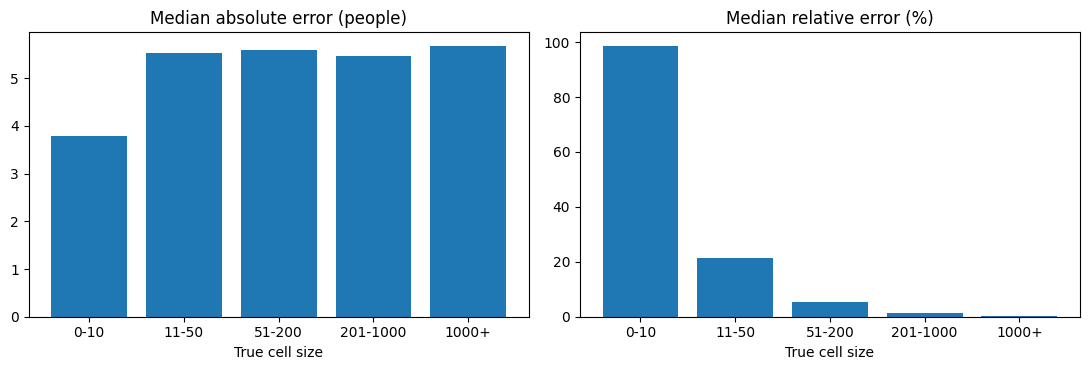

,cells,median_abs_err,median_rel_err
bucket,,,
0-10,151.0,3.80,9.87e-01
11-50,356.0,5.54,2.15e-01
51-200,454.0,5.60,5.41e-02
201-1000,329.0,5.46,1.44e-02
1000+,30.0,5.68,4.04e-03


In [67]:
# >>>>>>>>>>>>>>>>  EDIT THESE  <<<<<<<<<<<<<<<<
EPS_TOTAL = 1.0
RELEASE = ["race", "age", "poverty", "nativity", "disability",
           "pov_by_race", "pov_by_age", "pov_by_nativity", "pov_by_disability"] # delete names to drop tables
WEIGHTS = {}                                                                    # optional, e.g. {"poverty": 3}
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

ALLOC = make_alloc(RELEASE, WEIGHTS)
my_result = run_trials(EPS_TOTAL, ALLOC, trials=50, seed=11)
my_table = show_results(my_result, "YOUR SETTING")
my_table

## 6. The whole tradeoff curve

This sweeps ε from very private to barely private and plots accuracy against it. Look for where the curve flattens: **is there a "knee"? Who decides that it is good enough?**

,flips_all,flips_near_line,median_rel_err_small_cells_pct,median_rel_err_large_cells_pct
epsilon,,,,
0.05,14.90,5.67,100.00,33.09
0.10,12.33,5.13,100.00,16.55
0.25,7.07,3.70,93.81,6.64
0.50,4.00,2.70,47.77,3.31
1.00,2.03,1.77,23.88,1.67
2.00,1.03,0.97,11.99,0.84
5.00,0.33,0.33,5.05,0.36
10.00,0.03,0.03,2.59,0.17


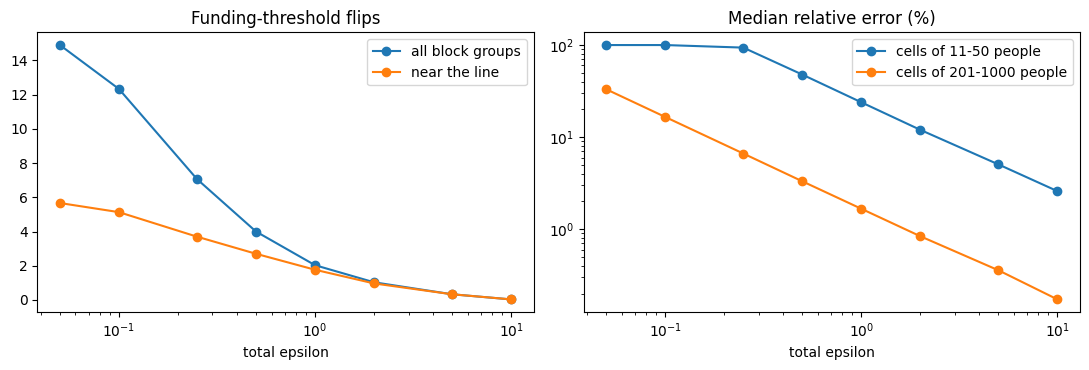

In [59]:
sweep_eps = [0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10]
equal = EQUAL
rows = []
for e in sweep_eps:
    r = run_trials(e, equal, trials=30, seed=5)
    rows.append({"epsilon": e,
                 "flips_all": r["flips"],
                 "flips_near_line": r["near_flips"],
                 "median_rel_err_small_cells_pct": r["by_bucket"].loc["11-50", "median_rel_err"] * 100,
                 "median_rel_err_large_cells_pct": r["by_bucket"].loc["201-1000", "median_rel_err"] * 100})
sweep = pd.DataFrame(rows).set_index("epsilon")
display(sweep) if "display" in globals() else print(sweep)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sweep.index, sweep.flips_all, marker="o", label="all block groups")
ax[0].plot(sweep.index, sweep.flips_near_line, marker="o", label="near the line")
ax[0].set_xscale("log"); ax[0].set_xlabel("total epsilon"); ax[0].set_title("Funding-threshold flips")
ax[0].legend()
ax[1].plot(sweep.index, sweep.median_rel_err_small_cells_pct, marker="o", label="cells of 11-50 people")
ax[1].plot(sweep.index, sweep.median_rel_err_large_cells_pct, marker="o", label="cells of 201-1000 people")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("total epsilon")
ax[1].set_title("Median relative error (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Composition: why "ε = 1" means nothing without the whole budget

If the city releases `k` tables and holds the **total** at ε = 1, each table gets ε/k, so noise per table grows with `k`. Alternatively, if the city gives each table ε = 1, the person's **total** privacy loss is `k`.

Be ready to answer: **when someone says "this release satisfies ε = 1," what exactly did they count?**

In [60]:
rows = []
for k in [1, 2, 4, 8, 16, 32]:
    rows.append({"tables released (k)": k,
                 "eps per table if total fixed at 1": 1 / k,
                 "noise std per table (people)": np.sqrt(2) * k,
                 "total eps if each table gets eps=1": k})
pd.DataFrame(rows).set_index("tables released (k)")

,eps per table if total fixed at 1,noise std per table (people),total eps if each table gets eps=1
tables released (k),,,
1,1.00,1.41,1
2,0.50,2.83,2
4,0.25,5.66,4
8,0.12,11.31,8
16,0.06,22.63,16
32,0.03,45.25,32


## 8. Cross-tabs make other tables redundant -- at what price?

`pov_by_race` already contains everything in the one-way `race` and `poverty` tables: add up its cells and you get them back. Adding up noisy cells costs **no extra privacy** (it is post-processing). So a city could release **only the three cross-tabs** and spend ε/3 on each, instead of releasing all seven tables at ε/7 each.

The cell below compares the two designs at the same total ε. **Design A:** seven tables, equal split. **Design B:** three cross-tabs only, with the one-way tables *derived* by summing cells. You can try this yourself in Section 5 by editing `RELEASE`.

Be ready to discuss: Design B looks better on accuracy. What does it cost? (Think about who loses a published table, and about errors adding up when many cells are summed.)

In [61]:
CROSS_ONLY = make_alloc(["pov_by_race", "pov_by_age", "pov_by_nativity", "pov_by_disability"])

rows = []
for e in [0.5, 1, 2]:
    err = {(d, k): [] for d in "AB" for k in ("pov_by_race", "race")}
    for t in range(100):
        rng = np.random.default_rng(t)
        for d, al in (("A", EQUAL), ("B", CROSS_ONLY)):
            eff = effective_tables(release(TRUE, e, al, rng))
            for k in ("pov_by_race", "race"):
                err[(d, k)].append(np.abs(eff[k].to_numpy() - TRUE[k].to_numpy()).mean())
    rows.append({"total eps": e,
                 "pov_by_race error, A (7 tables)": np.mean(err[("A", "pov_by_race")]),
                 "pov_by_race error, B (3 cross-tabs)": np.mean(err[("B", "pov_by_race")]),
                 "race error, A": np.mean(err[("A", "race")]),
                 "race error, B (derived)": np.mean(err[("B", "race")])})
pd.DataFrame(rows).set_index("total eps")

,"pov_by_race error, A (7 tables)","pov_by_race error, B (3 cross-tabs)","race error, A","race error, B (derived)"
total eps,,,,
0.5,15.33,7.30,16.85,11.09
1.0,8.15,3.78,8.72,5.73
2.0,4.24,1.92,4.42,2.93


## 9. What does ε buy you? A membership-inference test

An attacker knows everything about a block group **except whether one particular person is in it**. They see one noisy count and guess "in" or "out." DP promises their accuracy can't beat roughly `e^ε / (1 + e^ε)` (for a guess based on that single count, 50% is pure chance).

Remember that each person appears in **seven** tables. If an attacker combines all seven, the relevant ε is the **total**, not the per-table amount.

         attacker accuracy (simulated)  DP upper bound
epsilon                                               
0.1                               0.53            0.53
0.5                               0.61            0.62
1.0                               0.70            0.73
2.0                               0.82            0.88
5.0                               0.96            0.99
10.0                              1.00            1.00


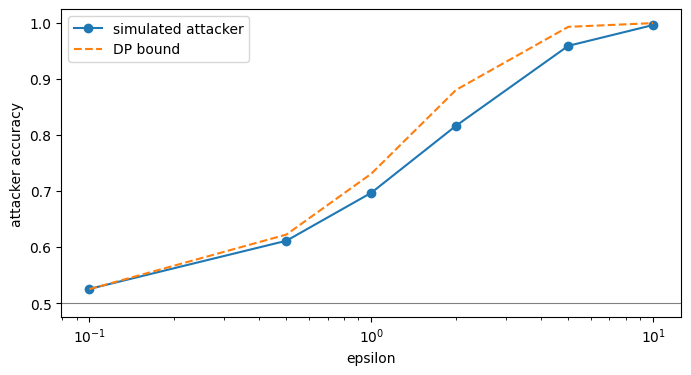

In [62]:
def membership_attack(eps, trials=200_000, seed=0):
    rng = np.random.default_rng(seed)
    c = 40                                    # true count if the person is out
    out_world = c     + rng.laplace(0, 1 / eps, trials)
    in_world  = c + 1 + rng.laplace(0, 1 / eps, trials)
    guess_in_when_in  = (in_world  > c + 0.5).mean()
    guess_out_when_out = (out_world <= c + 0.5).mean()
    return (guess_in_when_in + guess_out_when_out) / 2

rows = []
for e in [0.1, 0.5, 1, 2, 5, 10]:
    rows.append({"epsilon": e,
                 "attacker accuracy (simulated)": membership_attack(e),
                 "DP upper bound": np.exp(e) / (1 + np.exp(e))})
atk = pd.DataFrame(rows).set_index("epsilon")
print(atk.round(3).to_string())

plt.plot(atk.index, atk.iloc[:, 0], marker="o", label="simulated attacker")
plt.plot(atk.index, atk.iloc[:, 1], "--", label="DP bound")
plt.axhline(0.5, color="gray", lw=0.8); plt.xscale("log")
plt.xlabel("epsilon"); plt.ylabel("attacker accuracy"); plt.legend(); plt.show()

**Discussion prompts.** An attacker at ε = 1 is right roughly 70% of the time instead of 50%. Is that "protection"? Does your answer change if the thing being guessed is immigration status? What does the bound say about someone who is *not* in the dataset at all?

*Important limit:* this bound is about **one person's participation**. It does not stop inferences about groups (for example, "block group 7 has a high poverty rate"), since that is the whole point of publishing statistics.

### Optional: interactive sliders
If controls appear below, use them: tick the tables to release and drag the sliders. (They need `ipywidgets`, which Colab and most Jupyter installs include.)

In [63]:
try:
    import ipywidgets as w
    from IPython.display import display
    eps_slider = w.FloatLogSlider(value=1, base=10, min=-2, max=1.3, step=0.05, description="total eps")
    checks  = {t: w.Checkbox(value=True, description=t, indent=False) for t in TABLES}
    weights = {t: w.FloatSlider(value=1, min=0.1, max=5, step=0.1, description="weight") for t in TABLES}
    def explore(eps, **kw):
        alloc = {t: kw["w_" + t] for t in TABLES if kw["inc_" + t]}
        if not alloc:
            print("Tick at least one table."); return
        show_results(run_trials(eps, alloc, trials=10, seed=1), "Interactive")
    controls = {"eps": eps_slider,
                **{"inc_" + t: checks[t] for t in TABLES}, **{"w_" + t: weights[t] for t in TABLES}}
    out = w.interactive_output(explore, controls)
    display(w.VBox([eps_slider, *[w.HBox([checks[t], weights[t]]) for t in TABLES]]), out)
except ImportError:
    print("ipywidgets not installed; use the Section 5 control panel instead.")

Output()

## 10. Team worksheet: your proposal

Fill in the dictionary below (including **which tables you release**), run the cell, and **paste its output into your joint memo**. Then answer the questions beneath it in writing. Lawyers: these answers are the factual record for your rationale. Engineers: be ready to explain each number in plain English.

In [64]:
# >>>>>>>>>>>>>>>>  FILL IN  <<<<<<<<<<<<<<<<
PROPOSAL = {
    "team": "Team name",
    "eps_total": 1.0,
    "release": ["race", "age", "poverty", "nativity",
                "pov_by_race", "pov_by_age", "pov_by_nativity"],   # which tables? delete names to drop
    "weights": {},                                                  # optional, e.g. {"poverty": 3}
    "disclose_publicly": ["epsilon", "allocation", "error rates"],  # what will the city publish?
}
# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

def print_proposal(p):
    alloc = make_alloc(p["release"], p["weights"])
    r = run_trials(p["eps_total"], alloc, trials=100, seed=42)
    eps_t = split_budget(p["eps_total"], alloc)
    src = sources(list(eps_t))
    print(f"PROPOSAL: {p['team']}")
    print(f"Total epsilon: {p['eps_total']}")
    print(f"Tables released ({len(eps_t)}), epsilon each:", {k: round(v, 3) for k, v in eps_t.items()})
    print("Tables users can derive for free:", {k: v for k, v in src.items() if v.startswith("derived")} or "none")
    print("Tables NOT available:", [k for k, v in src.items() if v == "NOT AVAILABLE"] or "none")
    print(f"Publicly disclosed: {', '.join(p['disclose_publicly'])}")
    if np.isnan(r["flips"]):
        print("Funding-threshold test: cannot be run (no released table contains poverty status).")
    else:
        print(f"Funding-threshold errors: {r['flips']:.1f} of {len(TRUE['poverty'])} block groups "
              f"({r['near_flips']:.1f} of {r['near_n']} near the line)")
    print("Median relative error by table (%):",
          {k: round(v * 100, 1) for k, v in r["by_table"].dropna().items()})
    print("Median relative error by true cell size:")
    print((r["by_bucket"].median_rel_err * 100).round(1).astype(str).add("%").to_string())

print_proposal(PROPOSAL)

PROPOSAL: Team name
Total epsilon: 1.0
Tables released (7), epsilon each: {'race': 0.143, 'age': 0.143, 'nativity': 0.143, 'poverty': 0.143, 'pov_by_race': 0.143, 'pov_by_age': 0.143, 'pov_by_nativity': 0.143}
Tables users can derive for free: none
Tables NOT available: ['disability', 'pov_by_disability']
Publicly disclosed: epsilon, allocation, error rates
Funding-threshold errors: 1.5 of 40 block groups (1.3 of 13 near the line)
Median relative error by table (%): {'race': 5.5, 'age': 3.5, 'nativity': 2.2, 'poverty': 1.9, 'pov_by_race': 13.3, 'pov_by_age': 8.2, 'pov_by_nativity': 5.2}
Median relative error by true cell size:
bucket
0-10        98.0%
11-50       18.8%
51-200       4.8%
201-1000     1.3%
1000+        0.3%


**Written questions for the memo**

1. Which tables did you drop (or derive), and who loses out? Whose data is least accurate under your proposal, and who bears the cost of that inaccuracy?
2. What is the strongest argument *against* your ε from another team's role? How do you answer it?
3. How would you explain "total ε = ___" to a resident in two sentences, with no jargon?
4. What would you need to document for this decision to survive review as reasoned rather than arbitrary?
5. What did the other discipline notice that you would have missed?

---
*Teaching note: the synthetic data, Laplace mechanism, and simple composition used here are deliberately simplified. Real systems, such as the 2020 Census TopDown algorithm, use more sophisticated mechanisms, post-processing, and invariants.*